# Statistical learning and data mining Assignment 7

#### Student ID:

#### Name:

### **Assignment Information**

* **Course:** Statistical Learning and Data Mining
* **Covered Chapters:**
    * Chapter 7: Moving Beyond Linearity (70 points)
    * Chapter 8: Tree-Based Methods (30 points)
* **Due Date:** **November 26, 2026 (Thursday) 23:59**
* **Submission:** Please convert the completed `.ipynb` file to a `.pdf` file and upload it to the NSYSU e-Learning platform: [https://elearn.nsysu.edu.tw/course/33327/homework#/](https://elearn.nsysu.edu.tw/course/33327/homework#/)
* **File Naming Convention:** `HW7_StudentID_Name.pdf`

---

### **Instructions & Notes**

1. Please answer each question in the corresponding cell provided below it.
2. For **theoretical questions**, use a **Markdown cell** to write your answers. You are encouraged to use LaTeX for mathematical formulas (e.g., `$Y = f(X) + \epsilon$`). If you find this difficult, you may write your answers on paper, take a picture, and embed the image in the cell.
3. For **practical (coding) questions**, use a **Code cell** to write your code. Ensure that the code can be executed successfully and that all required outputs (e.g., text, plots, etc.) are displayed.
4. It is highly recommended to add comments to the **key parts** of your code to help us understand your logic.
5. Discussion with classmates is permitted, but **plagiarism is strictly forbidden**.

# Chapter 7 - Moving Beyond Linearity

### Q1 (32 points): This question uses the variables dis (the weighted mean of distances to five Boston employment centers) and nox (nitrogen oxides concentration in parts per 10 million) from the Boston data. We will treat dis as the predictor and nox as the response.

<Axes: xlabel='dis', ylabel='nox'>

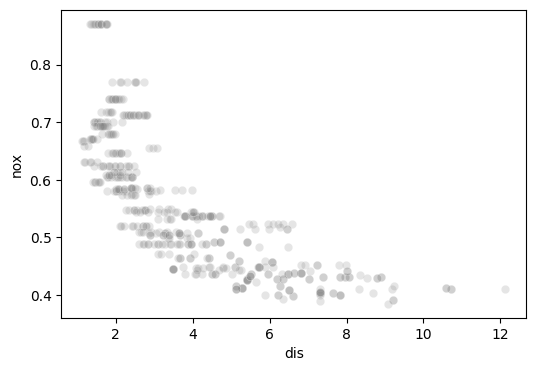

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


Boston = pd.read_csv('https://github.com/intro-stat-learning/ISLP/blob/main/ISLP/data/Boston.csv?raw=true')
dis = Boston.pop('dis')
nox = Boston.pop('nox')

fig, ax = plt.subplots(figsize=(6, 4))
sns.scatterplot(x=dis, y=nox, color='tab:gray', alpha=0.2, ax=ax)

(a) Plot the polynomial fits using the `sns.regplot` function (set `ax=ax` and `scatter=False`) with polynomial degrees (`order=n`) from 1 to 9. (8 points)

In [ ]:
import statsmodels.api as sm
from sklearn.preprocessing import PolynomialFeatures

fig, axes = plt.subplots(3, 3, sharex=True, sharey=True, figsize=(9, 9))
for i, axs in enumerate(axes):
    for j, ax in enumerate(axs):
        n = 1+j+3*i
        sns.scatterplot(x=dis, y=nox, color='tab:gray', alpha=0.2, ax=ax)
        # __________plot__________
        ax.set(title = 'Degree = ' + str(n))
        ax.axes.set_ylim(0.35,0.9)

(b) Report the associated residual sum of squares using the `sm.OLS` and the `PolynomialFeatures` function. (8 points)

In [ ]:
scores = []
for n in range(1, 9+1):
  # _____________calculate_rss_____
  rss = # _____calculate_rss_____
  print('Degree', n, ':', rss)
  scores.append(rss)

fig, ax = plt.subplots(figsize=(6, 4))
sns.lineplot(x=range(1, 9+1), y=scores, ax=ax, marker="o")
min_score_index = np.argmin(scores)+1
plt.plot(min_score_index, min(scores), marker = 'o', markersize = 8, color = 'r')
ax.text(min_score_index-1.2, min(scores)+0.1, round(min(scores), 6), size=12)
plt.xlabel('Degree')
plt.ylabel('Residual Sum of Squares')

(c) Perform cross-validation using the `cross_val_score` function (set `cv = 10`) to select the optimal degree for the polynomial. (10 points)

In [ ]:
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import cross_val_score
from sklearn.preprocessing import PolynomialFeatures

scores = []
fig, ax = plt.subplots(figsize=(6, 4))
for n in range(1, 9+1):
  # _____________calculate_mse_____
  mse = # _______________mse_____
  scores.append(mse)

sns.lineplot(x=range(1, 9+1), y=scores, ax=ax, marker="o")
min_score_index = np.argmin(scores)+1
plt.plot(min_score_index, min(scores), marker = 'o', markersize = 8, color = 'r')
ax.text(min_score_index-1.2, min(scores)+0.1, round(min(scores), 6), size=12)
plt.xlabel('Degree')
plt.ylabel('10-CV mean squared error')
plt.show()

(d) Describe what you observed from (b) and (c). 勿超過一行。 (6 points)

> Ans:  


這題的旨意是讓大家比較加入次方項之後，training RSS 與 10-fold CV error 的變化有什麼不同，並由此得出 (d) 的結論。(d) 的結論可以推廣到本週其他的模型，只是那些模型在 python 中較難用，有興趣的同學可以自行透過 Lab 練習。

### Q2 (38 points): Regression Splines.

A cubic regression spline with one knot at $\xi$ can be obtained using a basis of the form $x$, $x^2$, $x^3$, $(x − \xi)_+^3$, where $(x − \xi)_+^3 = (x − \xi)^3$ if $x > \xi$ and equals 0 otherwise. We will now show that a function of the form
$$f(x)=\beta_0+\beta_1x+\beta_2x^2+\beta_3x^3+\beta_4 (x − \xi)_+^3$$
is indeed a cubic regression spline, regardless of the values of $\beta_0$, $\beta_1$, $\beta_2$, $\beta_3$, $\beta_4$.

(a) Find a cubic polynomial
$$f_1(x)=a_1+b_1x+c_1x^2+d_1x^3$$
such that $f(x)=f_1(x)$ for all $x\leq \xi$. Express $a_1$, $b_1$, $c_1$, $d_1$ in terms of $\beta_0$, $\beta_1$, $\beta_2$, $\beta_3$, $\beta_4$. (5 points)

> Ans:  

(b) Find a cubic polynomial
$$f_2(x)=a_2+b_2x+c_2x^2+d_2x^3$$
such that $f(x)=f_2(x)$ for all $x> \xi$. Express $a_2$, $b_2$, $c_2$, $d_2$ in terms of $\beta_0$, $\beta_1$, $\beta_2$, $\beta_3$, $\beta_4$. We have now establised that $f(x)$ is a piecewise polynomial. (9 points)

> Ans:  

(c) Show that $f_1(\xi) = f_2(\xi)$. That is, $f(x)$ is continuous at $\xi$. (8 points)

> Ans:  


(d) Show that $f'_1(\xi) = f'_2(\xi)$. That is, $f'(x)$ is continuous at $\xi$. (8 points)

> Ans:  


(e) Show that $f''_1(\xi) = f''_2(\xi)$. That is, $f''(x)$ is continuous at $\xi$. (8 points)

> Ans:  


# Chapter 8 - Tree-Based Methods

### Q3 (30 points):
#### For the following pair of figures, where the left figure is a partition of two dimensional feature space and the right one is a decision tree, write down the correct regions $R_1, R_2, \dots, R_6$ for the (a) to (f), cutpoints $t_1$ and $t_5$ for (g) and (h), and criteria for (i), (j), and (k). ((a)–(f): 2 points each; (g)(h): 3 points each; (i)–(k): 4 points each)

&nbsp;&nbsp;$10$&nbsp;|---------------|-------------------------|---------------|  
&emsp;&emsp;|&emsp;&emsp;&emsp;&emsp;|&emsp;&emsp;&emsp;&emsp;&emsp;&emsp;&emsp;|&emsp;&nbsp;&nbsp;(a)&emsp;&nbsp;&nbsp;|  &emsp;&emsp;&emsp;$X_1 \leq t_1$  
&emsp;&emsp;|&emsp;&emsp;&emsp;&emsp;|&emsp;&emsp;&emsp;&emsp;&emsp;&emsp;&emsp;|&emsp;&emsp;&emsp;&emsp;&nbsp;|  &emsp;&emsp;&emsp;&emsp;&emsp;|&emsp;&emsp;&nbsp;(i)  
&emsp;&emsp;|&emsp;&emsp;&emsp;&emsp;|&emsp;&emsp;&emsp;&emsp;&emsp;&nbsp;&nbsp;(g)&nbsp;|---------------|  &emsp;&emsp;|----------|----------|  
&emsp;&emsp;|&emsp;&emsp;&emsp;&emsp;|&emsp;&emsp;&nbsp;&nbsp;&nbsp;(b)&emsp;&emsp;&emsp;|&emsp;&emsp;&emsp;&emsp;&nbsp;|  &emsp;&emsp;|&emsp;&emsp;&emsp;&emsp;&emsp;&nbsp;&nbsp;&nbsp;|  
&emsp;&emsp;|&emsp;&nbsp;&nbsp;(c)&emsp;&nbsp;|&emsp;&emsp;&emsp;&emsp;&emsp;&emsp;&emsp;|&emsp;&emsp;&emsp;&emsp;&nbsp;|  &emsp;&emsp;|&emsp;&emsp;&nbsp;&nbsp;&nbsp;(j)&emsp;&emsp;|&emsp;&nbsp;&nbsp;&nbsp;(k)  
&emsp;&emsp;|&emsp;&emsp;&emsp;&emsp;|&emsp;&emsp;&emsp;&emsp;&emsp;&emsp;&emsp;|&emsp;&nbsp;$R_6$&emsp;&nbsp;&nbsp;|  &emsp;&emsp;|&emsp;&emsp;&emsp;|---------|--------|  
$X_2$&nbsp;&nbsp;|&emsp;&emsp;&emsp;&emsp;|&emsp;&emsp;&emsp;&emsp;&emsp;&emsp;&emsp;|&emsp;&emsp;&emsp;&emsp;&nbsp;|  &emsp;&emsp;|&emsp;&emsp;&emsp;|&emsp;&emsp;&emsp;&emsp;&nbsp;&nbsp;&nbsp;|&emsp;$X_2 \geq t_5$  
&emsp;&emsp;|&emsp;&emsp;&emsp;$t_2$|---------------|----------|---------------|  &emsp;&emsp;|&emsp;&emsp;&emsp;|&emsp;&emsp;&emsp;&nbsp;|-----|-----|  
&emsp;&emsp;|&emsp;&emsp;&emsp;&emsp;|&emsp;&emsp;&emsp;&emsp;|&emsp;&emsp;&nbsp;&nbsp;&nbsp;$t_3$&emsp;&emsp;&emsp;&nbsp;&nbsp;|  &emsp;&emsp;|&emsp;&emsp;&emsp;|&emsp;&emsp;&emsp;&nbsp;|&emsp;&emsp;&emsp;|  
&emsp;&emsp;|&emsp;&emsp;&emsp;&emsp;|&emsp;$R_2$&emsp;&nbsp;&nbsp;|&emsp;&emsp;&emsp;(d)&emsp;&emsp;&emsp;|  &emsp;&emsp;|&emsp;&emsp;|---|---|&emsp;&emsp;&nbsp;|&emsp;&emsp;|---|---|  
&emsp;&emsp;|&emsp;&emsp;&emsp;&emsp;|&emsp;&emsp;&emsp;&emsp;|&emsp;&emsp;&emsp;&emsp;&emsp;&emsp;&emsp;&nbsp;|  &emsp;&emsp;|&emsp;&emsp;|&emsp;&emsp;|&emsp;&emsp;|&emsp;&emsp;|&emsp;&emsp;|  
&emsp;$0$&nbsp;|---------------|---------------|--------------------------|  &emsp;&nbsp;&nbsp;$R_1$&nbsp;&nbsp;&nbsp;(e)&emsp;$R_3$&nbsp;&nbsp;&nbsp;$R_4$&emsp;$R_5$&nbsp;&nbsp;&nbsp;(f)  
&emsp;&nbsp;&nbsp;&nbsp;$0$&emsp;&emsp;&emsp;&nbsp;&nbsp;(h)&emsp;&nbsp;&emsp;&emsp;&nbsp;$t_4$&emsp;&emsp;&emsp;&emsp;&emsp;&emsp;$10$  
&emsp;&emsp;&emsp;&emsp;&emsp;&emsp;&emsp;&emsp;&emsp;&emsp;$X_1$  
&emsp;  

> Ans:  
(a)  
(b)  
(c)  
(d)  
(e)  
(f)  
(g)  
(h)  
(i)  
(j)  
(k)